In [148]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [149]:
def augustus_refs(df):
    out_df= pd.DataFrame()
    accessions=df["accession"].unique().tolist()
    for acc in accessions:    
        busco = pd.read_csv(f"input/ref_sets/new_ids/busco_{acc}.txt", header=None)
        house = pd.read_csv(f"input/ref_sets/new_ids/housekeeping_{acc}.txt", header=None)
        nlr = pd.read_csv(f"input/ref_sets/new_ids/nlrs_v2_{acc}.txt", header=None)

        busco["type"] = "busco"
        house["type"] = "housekeeping"
        nlr["type"] = "nlr"
        gene_type = pd.concat([busco,house,nlr])
        gene_type.columns = ["ref_isoform","type"]
        gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

        gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
        gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"

        sub=df.loc[df["accession"]==acc]
        sub = pd.merge(left=sub, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')

        
        out_df=pd.concat([out_df,sub])
    return out_df

In [150]:
def subsample(df, len_nlr, refname):
        ### Random subsampling form the genome
        # Preparation
        n=len_nlr
        exons_all, length_all, subs_all, cats_all=[],[],[],[]
        exons_dict, length_dict, subs_dict, cats_dict={},{},{},{}
        exons_final, length_final, subs_final, cats_final={},{},{},{}
        np.random.seed(42)
        seeds = np.random.choice(range(999999), size=10000, replace=False)

        # get snapshot of one iteration
        for i in range(len(seeds)):
            sub_df = df.sample(n, random_state=seeds[i], axis=0)
            exons_all.append(sub_df["exons"])
            length_all.append(sub_df["length"])
            subs_all.append(sub_df["subcategory"])
            cats_all.append(sub_df["structural_category"])

        # count occurences of all snapshots
        for subset in exons_all:
            for gene in subset:
                if gene in exons_dict.keys():
                    exons_dict[gene] +=1
                else:
                    exons_dict[gene] = 1

        for subset in length_all:
            for gene in subset:
                if gene in length_dict.keys():
                    length_dict[gene] +=1
                else:
                    length_dict[gene] = 1

        for subset in subs_all:
            for gene in subset:
                if gene in subs_dict.keys():
                    subs_dict[gene] +=1
                else:
                    subs_dict[gene] = 1
                    
        for subset in cats_all:
            for gene in subset:
                if gene in cats_dict.keys():
                    cats_dict[gene] +=1
                else:
                    cats_dict[gene] = 1

        # average the accumulated snaphot counts by the number of snapshots and get the probability by dividing all by all genes
        for key in exons_dict.keys():
            exons_final[key] = exons_dict[key]/len(seeds)

        for key in length_dict.keys():
            length_final[key] = length_dict[key]/len(seeds)

        for key in subs_dict.keys():
            subs_final[key] = subs_dict[key]/len(seeds)
            
        for key in cats_dict.keys():
            cats_final[key] = cats_dict[key]/len(seeds)
            
        exons_iters = pd.DataFrame.from_dict(exons_final, orient='index',columns=[f"{refname}_iters_exons"])
        exons_iters[f"{refname}_iters_exons_proportion"] = exons_iters[f"{refname}_iters_exons"]/n
        
        length_iters = pd.DataFrame.from_dict(length_final, orient='index',columns=[f"{refname}_iters_length"])
        length_iters[f"{refname}_iters_length_proportion"] = length_iters[f"{refname}_iters_length"]/n
        
        subs_iters = pd.DataFrame.from_dict(subs_final, orient='index',columns=[f"{refname}_iters_subs"])
        subs_iters[f"{refname}_iters_subs_proportion"] = subs_iters[f"{refname}_iters_subs"]/n
        
        cats_iters = pd.DataFrame.from_dict(cats_final, orient='index',columns=[f"{refname}_iters_cats"])
        cats_iters[f"{refname}_iters_cats_proportion"] = cats_iters[f"{refname}_iters_cats"]/n
        
        return exons_iters, length_iters, subs_iters, cats_iters

In [167]:
names=["hodgpodge"]
runs=["output/01/all_sqanti.pkl"]

df_exons=pd.DataFrame()
df_length=pd.DataFrame()
df_subs=pd.DataFrame()
df_cats=pd.DataFrame()

for name, run in zip(names,runs):
    # load full df
    ref=pd.read_pickle(f"{run}")
    
    # add new column
    ref["cat_assign"]="None"
    # and fill new colum based on 4 categories
    ref.loc[(ref["structural_category"] != "antisense") & (ref["structural_category"] != "fusion") & (ref["structural_category"] != "intergenic"), "cat_assign"]="one2one"
    ref.loc[(ref["structural_category"] == "antisense"), "cat_assign"]="antisense"
    ref.loc[(ref["structural_category"] == "fusion"), "cat_assign"]="fusion"
    ref.loc[(ref["structural_category"] == "intergenic") | (ref["structural_category"] == "genic_intron"), "cat_assign"]="novel"
    
    # in some cases, transcripts were reported as one2one even though the reads are spanning two genes.
    # In these cases, we have "fusion reads", but splicing results in perfect cds for one gene.
    # filter them and add replace the assignment
    span = 2
    ref["association"]=ref["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)]).str.len()
    ref.loc[(ref["cat_assign"]=="one2one")&(ref["association"]>1), "cat_assign"] = "fusion"
    
    ref = ref.loc[ref["cat_assign"]=="one2one"]
    
    ref =augustus_refs(ref)
        
    ref["type"].fillna('other', inplace=True)
    
    
    
    
    #---------------------
    
    run_exons=pd.DataFrame()
    run_length=pd.DataFrame()
    run_subs=pd.DataFrame()
    run_cats=pd.DataFrame()

    for acc in tqdm(ref["accession"].unique().tolist()):
        at = ref.loc[ref["accession"] == acc].copy()
        nlr = at.loc[at["type"] == "nlr"].copy()
        busco = at.loc[at["type"] == "busco"].copy()
        house = at.loc[at["type"] == "housekeeping"].copy()
        n=min(len(nlr), len(busco), len(house), len(at))
        refsets=[nlr, busco, house, at]
        refnames=["nlr", "busco", "house","all"]
        
        refset_exons_iters=pd.DataFrame()
        refset_length_iters=pd.DataFrame()
        refset_subs_iters=pd.DataFrame()
        refset_cats_iters=pd.DataFrame()
        for refset, refname in zip(refsets, refnames):
            exons_iters, length_iters, subs_iters, cats_iters = subsample(refset, n, refname)
            refset_exons_iters=pd.concat([refset_exons_iters,exons_iters], axis="columns")
            refset_length_iters=pd.concat([refset_length_iters,length_iters], axis="columns")
            refset_subs_iters=pd.concat([refset_subs_iters,subs_iters], axis="columns")
            refset_cats_iters=pd.concat([refset_cats_iters,cats_iters], axis="columns")

            
        ### combine all
        # Take care of exons
        a=pd.DataFrame(nlr["exons"].value_counts())
        a.columns=["nlr_exons"]
        a["nlr_exons_proportion"]=a["nlr_exons"]/len(nlr)

        b=pd.DataFrame(busco["exons"].value_counts())
        b.columns=["busco_exons"]
        b["busco_exons_proportion"]=b["busco_exons"]/len(busco)

        c=pd.DataFrame(house["exons"].value_counts())
        c.columns=["housekeeping_exons"]
        c["housekeeping_exons_proportion"]=c["housekeeping_exons"]/len(house)

        e=pd.DataFrame(at["exons"].value_counts())
        e.columns=["all_exons"]
        e["all_exons_proportion"]=e["all_exons"]/len(at)
        
        acc_exons=pd.concat([a,refset_exons_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_exons["accession"] = acc
        run_exons=pd.concat([run_exons, acc_exons])

        ### combine all
        # Take care of length
        a=pd.DataFrame(nlr["length"].value_counts())
        a.columns=["nlr_length"]
        a["nlr_length_proportion"]=a["nlr_length"]/len(nlr)

        b=pd.DataFrame(busco["length"].value_counts())
        b.columns=["busco_length"]
        b["busco_length_proportion"]=b["busco_length"]/len(busco)

        c=pd.DataFrame(house["length"].value_counts())
        c.columns=["housekeeping_length"]
        c["housekeeping_length_proportion"]=c["housekeeping_length"]/len(house)

        e=pd.DataFrame(at["length"].value_counts())
        e.columns=["all_length"]
        e["all_length_proportion"]=e["all_length"]/len(at)

        acc_length=pd.concat([a,refset_length_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_length["accession"] = acc
        run_length=pd.concat([run_length, acc_length])

        ### combine all
        # Take care of subs
        a=pd.DataFrame(nlr["subcategory"].value_counts())
        a.columns=["nlr_subs"]
        a["nlr_subs_proportion"]=a["nlr_subs"]/len(nlr)

        b=pd.DataFrame(busco["subcategory"].value_counts())
        b.columns=["busco_subs"]
        b["busco_subs_proportion"]=b["busco_subs"]/len(busco)

        c=pd.DataFrame(house["subcategory"].value_counts())
        c.columns=["housekeeping_subs"]
        c["housekeeping_subs_proportion"]=c["housekeeping_subs"]/len(house)

        e=pd.DataFrame(at["subcategory"].value_counts())
        e.columns=["all_subs"]
        e["all_subs_proportion"]=e["all_subs"]/len(at)

        acc_subs=pd.concat([a,refset_subs_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_subs["accession"] = acc
        run_subs=pd.concat([run_subs, acc_subs])
    
        ### combine all
        # Take care of cats
        a=pd.DataFrame(nlr["structural_category"].value_counts())
        a.columns=["nlr_cats"]
        a["nlr_cats_proportion"]=a["nlr_cats"]/len(nlr)

        b=pd.DataFrame(busco["structural_category"].value_counts())
        b.columns=["busco_cats"]
        b["busco_cats_proportion"]=b["busco_cats"]/len(busco)

        c=pd.DataFrame(house["structural_category"].value_counts())
        c.columns=["housekeeping_cats"]
        c["housekeeping_cats_proportion"]=c["housekeeping_cats"]/len(house)

        e=pd.DataFrame(at["structural_category"].value_counts())
        e.columns=["all_cats"]
        e["all_cats_proportion"]=e["all_cats"]/len(at)

        acc_cats=pd.concat([a,refset_cats_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_cats["accession"] = acc
        run_cats=pd.concat([run_cats, acc_cats])
        
    df_exons=pd.concat([df_exons, run_exons])
    df_length=pd.concat([df_length, run_length])
    df_subs=pd.concat([df_subs, run_subs])
    df_cats=pd.concat([df_cats, run_cats])
    

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [55:05<00:00, 194.41s/it]


In [168]:
df_exons.to_pickle("output/clear_cases/exons_ava_nlrV2.pkl")
df_length.to_pickle("output/clear_cases/length_ava_nlrV2.pkl")
df_subs.to_pickle("output/clear_cases/subs_ava_nlrV2.pkl")
df_cats.to_pickle("output/clear_cases/cats_ava_nlrV2.pkl")

In [169]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [170]:
df_subs = pd.read_pickle("output/clear_cases/subs_ava_nlrV2.pkl")
df_length = pd.read_pickle("output/clear_cases/length_ava_nlrV2.pkl")
df_exons = pd.read_pickle("output/clear_cases/exons_ava_nlrV2.pkl")
df_cats = pd.read_pickle("output/clear_cases/cats_ava_nlrV2.pkl")

In [171]:
order=['reference_match','alternative_3end','alternative_5end','alternative_3end5end',
       '3prime_fragment','5prime_fragment','internal_fragment','multi-exon',
       'intron_retention',
       'combination_of_known_junctions','combination_of_known_splicesites','mono-exon_by_intron_retention','at_least_one_novel_splicesite',
       'mono-exon']

# Section 1: All vs All

What do I want to show here?
- What was udated by the 2 runs? Tama vs PB
- What was the impact on the individual annotations? Liftoff vs Augustus
- Is it ok to highlight only the inportant ones? Intron retention in general?
- Point towards augustus and Tama:
    - Tama has the advantage of error correction (splice sites) and the wobble walking, reducing the overall amount of updates
    - Augustus 
    - --> use hue=prediction and col=run

## 1.1) Sqanti subsections

In [172]:
sqanti_subs=df_subs[["index","accession","nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"]]

In [173]:
plot1=sqanti_subs.melt(id_vars=["index","accession"], value_vars=["nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"])

Text(-0.35, 0.33, 'n = 17')

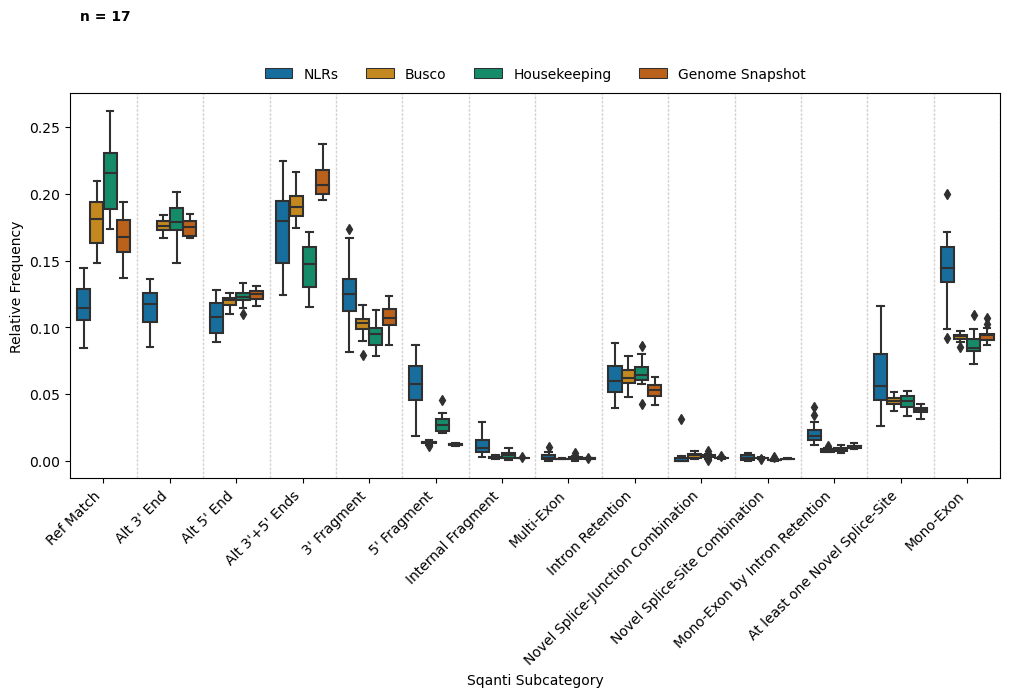

In [174]:
from matplotlib.pyplot import figure

plot1["variable_plot"] = plot1["variable"].map({'nlr_subs_proportion': 'NLRs', 'busco_subs_proportion': 'Busco', 'housekeeping_subs_proportion': 'Housekeeping', 'all_iters_subs_proportion':'Genome Snapshot'})
figure(figsize=(12, 5))

with sns.color_palette("colorblind"):
    p1_1=sns.boxplot(data=plot1, x="index", y="value", hue="variable_plot", order=order)
p1_1.set_xlabel("Sqanti Subcategory")
p1_1.set_ylabel("Relative Frequency")
p1_1.set_xticklabels(["Ref Match", "Alt 3' End", "Alt 5' End","Alt 3'+5' Ends","3' Fragment", "5' Fragment", 
                      "Internal Fragment", "Multi-Exon","Intron Retention",
                      "Novel Splice-Junction Combination","Novel Splice-Site Combination","Mono-Exon by Intron Retention",
                      "At least one Novel Splice-Site","Mono-Exon"],
                     rotation=45,
                     horizontalalignment='right')

# adding lines in general: https://community.dataquest.io/t/i-want-to-add-vertical-lines-in-a-sns-facetgrid-how-can-i-do-that/546424/2
#for i in range(len(plot1["index"].unique().tolist())):
#    p1_1.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)
[p1_1.axvline(x+.5,color='lightgrey', dashes=(2,1), linewidth=1) for x in p1_1.get_xticks()]


## https://stackoverflow.com/questions/60350781/edit-legend-title-and-labels-of-seaborn-scatterplot-and-countplot

#p1_1.legend(legend_handles, ['NLRs', 'Busco','Housekeeling','Full Genome'], title='Gene Sets', bbox_to_anchor=(1.05, 1))


#p1_1.legend(title='Gene Sets', bbox_to_anchor=(1.05, 1))
sns.move_legend(
    p1_1, "lower center",
    bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False,
)
plt.text(-0.35, 0.33, "n = 17", horizontalalignment='left', size='medium', color='black', weight='semibold')

In [175]:
fig = p1_1.get_figure()
fig.savefig("clear_cases_subcategories_per_accession_nlrV2.png", bbox_inches='tight', dpi=200)

### Get proportions per gene (hodgepodge)

In [151]:
hodge = pd.read_pickle("output/01/clear-fusion_tama_nlrV2_hodgepodge.pkl")

In [152]:
hodge

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,all_canonical,cat_assign,association,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
0,G1128,G1128.10,at6923,at6923_G016360,at6923_G016360_mRNA01,1,3275,1,59,full-splice_match,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,NaN,one2one,1,nlr,13,3,9.0
1,G1128,G1128.11,at6923,at6923_G016360,at6923_G016360_mRNA01,1,2744,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,NaN,one2one,1,nlr,13,3,3.0
2,G1128,G1128.12,at6923,at6923_G016360,at6923_G016360_mRNA01,1,2795,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,NaN,one2one,1,nlr,13,3,3.0
3,G1128,G1128.13,at6923,at6923_G016360,at6923_G016360_mRNA01,1,1821,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,NaN,one2one,1,nlr,13,3,3.0
4,G1128,G1128.2,at6923,at6923_G016360,novel,2,3331,1,59,genic,multi-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,canonical,one2one,1,nlr,13,3,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3262388,G16724,G16724.10,at9900,at9900_G337000_at9900_G336990,novel,5,2502,3,28,fusion,multi-exon,MAELKLSESRDLTRVERIGAHSHIRGLGLDSALEPRAVSEGMVGQV...,canonical,fusion,2,other,19,4,16.0
3262389,G16724,G16724.16,at9900,at9900_G337000_at9900_G336990,at9900_G336990_mRNA01,2,1810,1,28,full-splice_match,alternative_5end,MAELKLSESRDLTRVERIGAHSHIRGLGLDSALEPRAVSEGMVGQV...,canonical,fusion,2,other,19,4,16.0
3262390,G16724,G16724.17,at9900,at9900_G337000_at9900_G336990,novel,5,2482,1,28,fusion,multi-exon,MAELKLSESRDLTRVERIGAHSHIRGLGLDSALEPRAVSEGMVGQV...,canonical,fusion,2,other,19,4,16.0
3262391,G16724,G16724.19,at9900,at9900_G337000_at9900_G336990,novel,5,2381,1,28,fusion,multi-exon,MAELKLSESRDLTRVERIGAHSHIRGLGLDSALEPRAVSEGMVGQV...,canonical,fusion,2,other,19,4,16.0


In [153]:
hodge_proportions=pd.DataFrame()

for acc in tqdm(hodge["accession"].unique().tolist()):
    
    acc_df=hodge.loc[(hodge["accession"]==f"{acc}")].copy()
    props=pd.DataFrame()
    
    #nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")&(all_types["type"]=="nlr")].copy()
    for i in acc_df.groupby(by="gene", as_index=False):
        gene=pd.DataFrame({"accession":[acc],
                           "gene":[i[0]],
                           "type":[i[1]["type"].unique()[0]]})
        #gene["gene"]=i[0]
        for j in i[1].groupby(by="subcategory"):
            gene[j[0]]=j[1]["isoform_read_support"].sum()/i[1]["isoform_read_support"].sum()
        props=pd.concat([props, gene])        

    hodge_proportions=pd.concat([hodge_proportions,props])
    #print(nlr_acc.groupby(by="gene", as_index=False))
#var_scores_all.to_pickle("var_scores_nlr-other.pkl")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [14:36<00:00, 51.57s/it]


In [154]:
hodge_proportions

,accession,gene,type,alternative_5end,reference_match,alternative_3end,alternative_3end5end,at_least_one_novel_splicesite,mono-exon_by_intron_retention,intron_retention,3prime_fragment,mono-exon,multi-exon,5prime_fragment,internal_fragment,combination_of_known_splicesites,combination_of_known_junctions
0,at6923,G1,other,0.500000,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10,other,0.010989,0.351648,0.587912,0.032967,0.005495,0.010989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G100,other,0.500000,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G1000,other,0.100000,0.200000,0.150000,0.500000,NaN,NaN,0.050000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10000,other,NaN,0.700000,0.100000,NaN,NaN,0.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,at9900,G9994,other,NaN,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,NaN,NaN,NaN
0,at9900,G9995,other,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at9900,G9996,other,0.870968,0.021505,NaN,0.032258,0.021505,NaN,0.032258,0.021505,NaN,NaN,NaN,NaN,NaN,NaN
0,at9900,G9998,other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN


### Get proportions per gene (augustus)

In [155]:
aug = pd.read_pickle("../master_analysis/01_preparation/clear-fusion/clear-fusion_tama_augustus.pkl")

In [156]:
aug

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
0,G1128,G1128.10,at6923,g1555,novel,1,3275,1,59,genic,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
1,G1128,G1128.11,at6923,g1555,novel,1,2744,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
2,G1128,G1128.12,at6923,g1555,novel,1,2795,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
3,G1128,G1128.13,at6923,g1555,novel,1,1821,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
4,G1128,G1128.2,at6923,g1555,novel,2,3331,1,59,novel_not_in_catalog,intron_retention,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3419863,G16302,G16302.24,col0,ATCG01310_ATCG01300,novel,2,818,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,2.0
3419864,G16302,G16302.26,col0,ATCG01310_ATCG01300,novel,2,831,2,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419865,G16302,G16302.5,col0,ATCG01310_ATCG01300,novel,2,1204,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419866,G16302,G16302.7,col0,ATCG01310_ATCG01300,novel,2,1141,6,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0


In [157]:
aug_proportions=pd.DataFrame()

for acc in tqdm(aug["accession"].unique().tolist()):
    
    acc_df=aug.loc[(aug["accession"]==f"{acc}")].copy()
    props=pd.DataFrame()
    
    #nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")&(all_types["type"]=="nlr")].copy()
    for i in acc_df.groupby(by="gene", as_index=False):
        gene=pd.DataFrame({"accession":[acc],
                           "gene":[i[0]],
                           "type":[i[1]["type"].unique()[0]]})
        #gene["gene"]=i[0]
        for j in i[1].groupby(by="subcategory"):
            gene[j[0]]=j[1]["isoform_read_support"].sum()/i[1]["isoform_read_support"].sum()
        props=pd.concat([props, gene])        

    aug_proportions=pd.concat([aug_proportions,props])
    #print(nlr_acc.groupby(by="gene", as_index=False))
#var_scores_all.to_pickle("var_scores_nlr-other.pkl")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [14:23<00:00, 47.96s/it]


In [158]:
aug_proportions

,accession,gene,type,alternative_3end5end,3prime_fragment,alternative_3end,at_least_one_novel_splicesite,intron_retention,mono-exon,multi-exon,alternative_5end,combination_of_known_splicesites,reference_match,5prime_fragment,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions
0,at6923,G1,other,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10,other,0.934066,0.010989,0.032967,0.005495,0.005495,0.010989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G100,other,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G1000,other,0.250000,NaN,0.600000,0.050000,0.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10000,other,NaN,NaN,NaN,NaN,NaN,0.200000,0.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,col0,G9995,other,0.016393,0.229508,0.016393,0.081967,NaN,0.016393,NaN,0.426230,NaN,0.196721,0.016393,NaN,NaN,NaN
0,col0,G9996,other,0.050000,NaN,0.466667,0.050000,NaN,NaN,NaN,0.133333,NaN,0.300000,NaN,NaN,NaN,NaN
0,col0,G9997,other,NaN,NaN,0.125000,NaN,0.125000,NaN,NaN,0.125000,NaN,0.625000,NaN,NaN,NaN,NaN
0,col0,G9998,busco,NaN,NaN,0.375000,NaN,0.125000,NaN,NaN,0.125000,NaN,0.375000,NaN,NaN,NaN,NaN


### Get proportions per gene (liftoff)

In [159]:
lif = pd.read_pickle("../master_analysis/01_preparation/clear-fusion/clear-fusion_tama_liftoff.pkl")

In [160]:
lif

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
0,G1128,G1128.10,at6923,AT1G15890,AT1G15890.1,1,3275,1,59,full-splice_match,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,13,nlr,12,2,9.0
1,G1128,G1128.11,at6923,AT1G15890,AT1G15890.1,1,2744,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,13,nlr,12,2,3.0
2,G1128,G1128.12,at6923,AT1G15890,AT1G15890.1,1,2795,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,13,nlr,12,2,3.0
3,G1128,G1128.13,at6923,AT1G15890,AT1G15890.1,1,1821,1,59,full-splice_match,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,13,nlr,12,2,3.0
4,G1128,G1128.2,at6923,AT1G15890,novel,2,3331,1,59,genic,multi-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,13,nlr,12,2,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3410918,G16302,G16302.24,col0,ATCG01300_ATCG01310,novel,2,818,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,2.0
3410919,G16302,G16302.26,col0,ATCG01300_ATCG01310,novel,2,831,2,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3410920,G16302,G16302.5,col0,ATCG01300_ATCG01310,novel,2,1204,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3410921,G16302,G16302.7,col0,ATCG01300_ATCG01310,novel,2,1141,6,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0


In [161]:
lif_proportions=pd.DataFrame()

for acc in tqdm(lif["accession"].unique().tolist()):
    
    acc_df=lif.loc[(lif["accession"]==f"{acc}")].copy()
    props=pd.DataFrame()
    
    #nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")&(all_types["type"]=="nlr")].copy()
    for i in acc_df.groupby(by="gene", as_index=False):
        gene=pd.DataFrame({"accession":[acc],
                           "gene":[i[0]],
                           "type":[i[1]["type"].unique()[0]]})
        #gene["gene"]=i[0]
        for j in i[1].groupby(by="subcategory"):
            gene[j[0]]=j[1]["isoform_read_support"].sum()/i[1]["isoform_read_support"].sum()
        props=pd.concat([props, gene])        

    lif_proportions=pd.concat([lif_proportions,props])
    #print(nlr_acc.groupby(by="gene", as_index=False))
#var_scores_all.to_pickle("var_scores_nlr-other.pkl")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [17:53<00:00, 59.66s/it]


In [162]:
lif_proportions

,accession,gene,type,alternative_3end,reference_match,3prime_fragment,alternative_3end5end,alternative_5end,at_least_one_novel_splicesite,intron_retention,mono-exon_by_intron_retention,mono-exon,multi-exon,5prime_fragment,internal_fragment,combination_of_known_splicesites,combination_of_known_junctions
0,at6923,G1,other,0.500000,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10,other,0.472527,0.461538,0.010989,0.021978,0.010989,0.005495,0.005495,0.010989,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G100,other,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G1000,other,0.150000,0.200000,NaN,0.500000,0.100000,NaN,0.050000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,at6923,G10000,other,NaN,0.700000,NaN,NaN,NaN,NaN,0.100000,0.100000,0.100000,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,col0,G9995,other,0.016393,0.196721,0.229508,0.016393,0.426230,0.081967,NaN,NaN,0.016393,NaN,0.016393,NaN,NaN,NaN
0,col0,G9996,other,0.466667,0.300000,NaN,0.050000,0.133333,0.050000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,col0,G9997,other,0.125000,0.625000,NaN,NaN,0.125000,NaN,0.125000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,col0,G9998,busco,0.375000,0.375000,NaN,NaN,0.125000,NaN,0.125000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [163]:
hodge_proportions["run"]="hodgepodge"
aug_proportions["run"]="augustus"
lif_proportions["run"]="liftoff"

In [164]:
all_runs = pd.concat([hodge_proportions, aug_proportions, lif_proportions])

In [165]:
all_runs.fillna(0, inplace=True)

In [166]:
all_runs.to_pickle("output/02/all_runs_nlrV2_porportions.pkl")
all_runs.to_csv("output/02all_runs_nlrV2_porportions.tsv", sep="\t", index=False)